# Comparación de algoritmos de aprendizaje supervisado: KNN, SVM y red neuronal (MLP)

**Equipo:** CafeSmart **Integrantes:** Morales Mendez Shryley Nicoles, Jimenez Andrade Monserrat, Tejero Hernandez Rubi, Sarao Morales Rubi.

**Objetivo.** Implementar y comparar tres algoritmos (KNN, SVM y MLP) con el mismo conjunto de datos y la misma división de entrenamiento y prueba, para clasificar tumores de mama como **benignos** o **malignos** (dataset *Wisconsin Diagnostic Breast Cancer*, WDBC).

**Contenido:** 1. Carga y descripción de los datos · 2. Exploración · 3. Variables, división y preprocesamiento · 4. Entrenamiento y métricas · 5. Tabla comparativa y gráficas · 6. Ajuste de hiperparámetros (complemento) · 7. ¿Qué tan confiable es la comparación? · 8. Respuestas a las preguntas · 9. Conclusiones.

Todos los resultados salen de la ejecución de este notebook (semilla fija `SEED = 42`).

In [12]:
# Instalación de librerías.
# Quita "#" de la línea siguiente, ejecuta la celda y vuelve a comentarla.
#%pip install numpy pandas matplotlib scikit-learn jinja2

1. Carga y descripción de los datos
El archivo wdbc.data no trae encabezados: tiene el identificador, el diagnóstico (M o B) y 30 características numéricas. Los nombres se tomaron de wdbc.names: 10 medidas del núcleo celular (radio, textura, perímetro, área, suavidad, compacidad, concavidad, puntos cóncavos, simetría y dimensión fractal), cada una como media, error estándar y peor valor (el promedio de los tres valores más grandes).

In [13]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, RepeatedStratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
pd.set_option("display.max_columns", 40)

# --- Carga del archivo ---
URL_RAW = "https://github.com/strawrabbit0424/comparacion-knn-svm-mlp/blob/main/wdbc.data"   # opcional: URL "raw" de wdbc.data de repositorio de GitHub
RUTA = next((r for r in ["wdbc.data", "data/wdbc.data"] if os.path.exists(r)), None)
if RUTA is None and URL_RAW:
    RUTA = URL_RAW
if RUTA is None:
    try:
        from google.colab import files
        print("Sube el archivo wdbc.data")
        files.upload()
        RUTA = "wdbc.data"
    except ImportError:
        raise FileNotFoundError("No se encontró wdbc.data: colócalo junto al notebook.")

base = ["radius", "texture", "perimeter", "area", "smoothness",
        "compactness", "concavity", "concave_points", "symmetry", "fractal_dimension"]
columnas = ["id", "diagnosis"] + [f"{b}_{s}" for s in ("mean", "se", "worst") for b in base]
df = pd.read_csv(RUTA, header=None, names=columnas)
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [14]:
print("Registros (filas):", df.shape[0])
print("Columnas:", df.shape[1], "(1 identificador, 1 diagnóstico y", df.shape[1] - 2, "características numéricas)")
print("Valores nulos en total:", int(df.isnull().sum().sum()))
print("Identificadores repetidos:", int(df["id"].duplicated().sum()))
print("Tipos de dato:", df.drop(columns=["id", "diagnosis"]).dtypes.unique().tolist(), "(todas las características son numéricas)")
print()
conteo = df["diagnosis"].value_counts()
print("Clases a predecir (diagnosis):")
for k, nombre in [("B", "Benigno"), ("M", "Maligno")]:
    print(f"  {k} = {nombre}: {conteo[k]} registros ({100 * conteo[k] / len(df):.1f}%)")

Registros (filas): 569
Columnas: 32 (1 identificador, 1 diagnóstico y 30 características numéricas)
Valores nulos en total: 0
Identificadores repetidos: 0
Tipos de dato: [dtype('float64')] (todas las características son numéricas)

Clases a predecir (diagnosis):
  B = Benigno: 357 registros (62.7%)
  M = Maligno: 212 registros (37.3%)


## 2. Exploración

Se revisa el balance de las clases y la escala de las características, porque de ello depende el preprocesamiento.

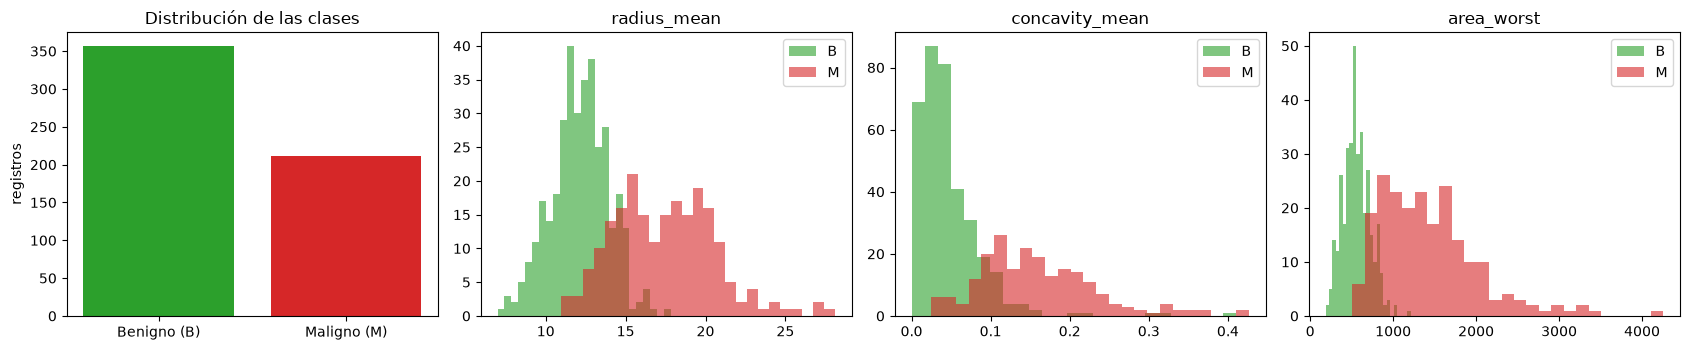

Rango de algunas características (muestra la diferencia de escalas):


,min,max
smoothness_mean,0.053,0.163
radius_mean,6.981,28.110
perimeter_mean,43.790,188.500
area_mean,143.500,2501.000
area_worst,185.200,4254.000


In [15]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
ax[0].bar(["Benigno (B)", "Maligno (M)"], [conteo["B"], conteo["M"]], color=["tab:green", "tab:red"])
ax[0].set_title("Distribución de las clases"); ax[0].set_ylabel("registros")
for i, col in enumerate(["radius_mean", "concavity_mean", "area_worst"], start=1):
    for k, color in [("B", "tab:green"), ("M", "tab:red")]:
        ax[i].hist(df.loc[df.diagnosis == k, col], bins=25, alpha=0.6, color=color, label=k)
    ax[i].set_title(col); ax[i].legend()
plt.tight_layout(); plt.show()

escala = df.drop(columns=["id", "diagnosis"]).agg(["min", "max"]).T
print("Rango de algunas características (muestra la diferencia de escalas):")
display(escala.loc[["smoothness_mean", "radius_mean", "perimeter_mean", "area_mean", "area_worst"]].round(3))

Lo que se observa: las clases están algo desbalanceadas (más benignos que malignos), por eso la división usará estratificación. Los tumores malignos tienden a tener radios, concavidades y áreas mayores, así que las características separan bastante bien las dos clases. Además, las escalas son muy distintas (por ejemplo, smoothness_mean va de 0.05 a 0.16 y area_worst llega a más de 4000), por lo que hay que estandarizar: KNN y SVM dependen de distancias, y la red neuronal converge mejor con entradas en una escala parecida.